# Первые ML-модели

## Цели и задачи этапа
**Цель этапа** – применить простые модели для решения задачи проекта.

**Задачи**:
1. Выбрать ключевую метрику для оценки качества моделей.
2. Применить простые модели машинного обучения:
    - Метрические подходы (KNN)
    - Линейные модели регрессии
3. Оценить качество обученных моделей с помощью выбранной метрики (метрик)
4. Подобрать гиперпараметры моделей и подумать над feature engineering для улучшения качества прогнозов с точки зрения выбранных метрик. Провести эксперименты.
5. Написать выводы по проделанной работе.


## Загрузка данных

Начнём с того, что подключим нужные библиотеки, откроем данные и проверим, что всё корректно подтянулось с этапа EDA.

Берём отмасштабированную версию датасета `borough-month-eda-scaled.csv`: числовые признаки в ней приведены к среднему 0 и стандартному отклонению 1, а таргеты `sales_count` и `price_median` и номер месяца `month_num` оставлены как есть.

In [256]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

RANDOM_STATE = 42

df = pd.read_csv("../dataset/data/borough-month-eda-scaled.csv", parse_dates=["month"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6072 entries, 0 to 6071
Data columns (total 16 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   month                                   6072 non-null   datetime64[us]
 1   borough                                 6072 non-null   str           
 2   sales_count                             6072 non-null   int64         
 3   price_median                            6072 non-null   float64       
 4   sales_count_lag12                       6072 non-null   float64       
 5   price_median_lag12                      6072 non-null   float64       
 6   year                                    6072 non-null   float64       
 7   month_num                               6072 non-null   int64         
 8   ptal                                    6072 non-null   float64       
 9   crime_per_1000_lag2                     6072 non-null   float64

In [257]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
month,6072,NaN,NaN,NaN,2018-01-15 09:23:28.695652,2010-06-01 00:00:00,2014-03-24 06:00:00,2018-01-16 12:00:00,2021-11-08 12:00:00,2025-09-01 00:00:00,NaN
borough,6072,33,Barking and Dagenham,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sales_count,6072.0,NaN,NaN,NaN,242.975626,3.0,174.0,226.5,292.0,1548.0,115.260904
price_median,6072.0,NaN,NaN,NaN,493822.274374,163000.0,355000.0,455000.0,559226.875,2195000.0,216784.855089
sales_count_lag12,6072.0,NaN,NaN,NaN,-0.0,-2.133778,-0.595948,-0.138154,0.435199,11.600023,1.000082
price_median_lag12,6072.0,NaN,NaN,NaN,0.0,-1.486943,-0.678022,-0.170576,0.321911,7.916333,1.000082
year,6072.0,NaN,NaN,NaN,-0.0,-1.707203,-0.806485,0.094233,0.769771,1.670489,1.000082
month_num,6072.0,NaN,NaN,NaN,6.521739,1.0,4.0,7.0,9.0,12.0,3.421692
ptal,6072.0,NaN,NaN,NaN,0.0,-0.749427,-0.554169,-0.36874,0.215723,5.019853,1.000082
crime_per_1000_lag2,6072.0,NaN,NaN,NaN,0.0,-1.134767,-0.531946,-0.211296,0.227353,9.687806,1.000082


## Разбиение на train и test

Все наблюдения собираются по месяцам, и месяцев у нас ровно 184 (июнь 2010 — сентябрь 2025). Поэтому делим данные **по месяцам, а не по строкам**: иначе часть районов одного месяца могла бы попасть в train, а часть — в test, и модель «подсмотрела» бы тестовый месяц через соседние районы.

Перемешивать данные тоже нельзя: модель должна прогнозировать будущее, поэтому тест — это последние месяцы. Берём 25% от 184 месяцев, то есть **последние 46 месяцев**. Это тестовый сет для вариантов 1–4.

In [258]:
months = df["month"].drop_duplicates().sort_values()
n_test_months = int(len(months) * 0.25)
cutoff = months.iloc[-n_test_months]  # первый месяц теста

train = df[df["month"] < cutoff]
test = df[df["month"] >= cutoff]

print(f"Train: {train['month'].min():%Y-%m} — {train['month'].max():%Y-%m}, {len(train)} строк")
print(f"Test:  {test['month'].min():%Y-%m} — {test['month'].max():%Y-%m}, {len(test)} строк")


Train: 2010-06 — 2021-11, 4554 строк
Test:  2021-12 — 2025-09, 1518 строк


## Модели для количества сделок `sales_count`

**Метрика.** Главная метрика — **MAE**: средняя ошибка в сделках, её легко объяснить («в среднем ошибаемся на N сделок в месяц по району»). Рядом смотрим **RMSE**, которая сильнее штрафует редкие большие промахи вроде всплесков перед изменениями налога, и **R²** — долю объяснённого разброса. MAPE не используем: в City of London бывает 3 сделки в месяц, и одна такая точка испортила бы всю метрику.

**Варианты моделей.** Каждый следующий вариант меняет предыдущий в одном месте, чтобы было видно, что именно дало эффект.

| Вариант | Что меняем | Тест |
|---|---|---|
| 1 | 8 числовых признаков из EDA, без дамми и лагов | последние 46 месяцев |
| 2 | + дамми районов, лаги продаж на 6 и 12 месяцев | последние 46 месяцев |
| 3 | 2 + лаги медианной цены на 6 и 12 месяцев | последние 46 месяцев |
| 4 | 2 без ставки Банка Англии `bank_rate` | последние 46 месяцев |
| 5а / 5б | признаки моделей 2 и 4 на новом разбиении | последние 30 месяцев |
| 6а / 6б | 5а без `ptal`; 6б — плюс лаг цены на 12 месяцев | последние 30 месяцев |
| 7 | 6а + сезонность (дамми месяцев) | последние 30 месяцев |
| 8 | 7 + флаги изменений налога SDLT | последние 30 месяцев |

Метрики сравниваем только между вариантами с одинаковым тестом: 1–4 между собой и 5–8 между собой.

### Вариант 1. Базовая линейная регрессия

Первая и самая простая модель — обычная линейная регрессия (OLS) без дамми-переменных, лагов и сезонности. Прогоняем её по числовым признакам, отобранным в EDA, и смотрим на MAE.

- **Признаки (8):** `ptal`, `crime_per_1000_lag2`, `floor_area_median_epc_prev_year`, `energy_efficiency_median_epc_prev_year`, `floor_height_median_epc_prev_year`, `bank_rate`, `mean_pay_prev_year`, `population_prev_2_years`.
- **Не используем:** `price_median` — цена за тот же месяц, на дату прогноза она неизвестна (утечка); `month` и `borough` — ключ и метка; лаги, `year` и `month_num` — оставляем на следующие варианты.
- **Тест:** последние 46 месяцев (декабрь 2021 — сентябрь 2025).

In [259]:
features = [
    "ptal",
    "crime_per_1000_lag2",
    "floor_area_median_epc_prev_year",
    "energy_efficiency_median_epc_prev_year",
    "floor_height_median_epc_prev_year",
    "bank_rate",
    "mean_pay_prev_year",
    "population_prev_2_years",
]
target = "sales_count"

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

In [260]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Коэффициенты:")
for feature, coef in zip(X_train.columns, model.coef_):
    print(f"  {feature:<40} {coef:>8.2f}")
print(f"  {'intercept':<40} {model.intercept_:>8.2f}")

print("\nОшибки:")
for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
    pred = model.predict(X)
    print(
        f"  {name:<5}  MAE = {mean_absolute_error(y, pred):6.1f}   "
        f"RMSE = {root_mean_squared_error(y, pred):6.1f}   "
        f"R² = {r2_score(y, pred):.3f}"
    )


Коэффициенты:
  ptal                                        12.85
  crime_per_1000_lag2                        -14.87
  floor_area_median_epc_prev_year             14.64
  energy_efficiency_median_epc_prev_year      -7.76
  floor_height_median_epc_prev_year          -14.42
  bank_rate                                  -11.29
  mean_pay_prev_year                          31.26
  population_prev_2_years                     68.05
  intercept                                  250.23

Ошибки:
  train  MAE =   68.4   RMSE =   98.3   R² = 0.315
  test   MAE =   67.9   RMSE =   89.2   R² = 0.210


**Вывод.** R² = 0.3 на тренировочном сете и 0.2 на тестовом.
1. Выбранные переменные описывают меньше трети флуктуаций целевой переменной.
2. Тест не может повторить результаты train: большое количество шоков (ковид, налоги) не учтено в тренировке.

Следующий шаг — добавить дамми-переменные районов и лаги по количеству сделок за предыдущие полгода и год.

### Вариант 2. Дамми районов и лаги продаж

Добавляем к модели 1 информацию о том, какой это район и как в нём шли продажи раньше.

- **Дамми районов:** 32 столбца (33 района, базовый — Barking and Dagenham). Коэффициент каждого района — поправка к уровню продаж относительно базового.
- **Лаги продаж:** `sales_count_lag12` (год назад, уже есть в датасете) и `sales_count_lag6` (полгода назад, строим сдвигом внутри каждого района). Заодно строим лаг цены на 6 месяцев — он понадобится в варианте 3.
- **Масштабирование:** новые лаги масштабируем как остальные признаки, но среднее и стандартное отклонение считаем только по train-месяцам, чтобы не было утечки.
- **Потеря данных:** у первых 6 месяцев (июнь–ноябрь 2010) нет лага на полгода, убираем их из train. Тест не меняется.
- **Тест:** последние 46 месяцев, сравниваем с моделью 1.

In [261]:
from sklearn.preprocessing import StandardScaler

lag6_cols = ["sales_count_lag6", "price_median_lag6"]

# 1. Лаги продаж и цены на 6 месяцев: сдвиг на 6 строк внутри каждого района
for col in ["sales_count", "price_median"]:
    df[f"{col}_lag6"] = df.groupby("borough")[col].shift(6)

# 2. Масштабируем лаги; среднее и std считаем только по train-месяцам
is_train = df["month"] < cutoff
scaler = StandardScaler()
scaler.fit(df.loc[is_train, lag6_cols])
df[lag6_cols] = scaler.transform(df[lag6_cols])

# 3. Дамми районов: 33 района -> 32 столбца
borough_dummies = pd.get_dummies(df["borough"], prefix="borough", drop_first=True, dtype=int)
df[borough_dummies.columns] = borough_dummies

# 4. Пересобираем train и test; первые 6 месяцев без лага убираем
train = df[is_train].dropna(subset=lag6_cols)
test = df[~is_train]
print(len(train), len(test))

4356 1518


In [262]:
features_v2 = features + ["sales_count_lag12", "sales_count_lag6"] + borough_dummies.columns.tolist()

X_train_v2, X_test_v2 = train[features_v2], test[features_v2]
y_train_v2, y_test_v2 = train["sales_count"], test["sales_count"]


In [263]:
model_v2 = LinearRegression()
model_v2.fit(X_train_v2, y_train_v2)

print("Коэффициенты:")
for feature, coef in zip(X_train_v2.columns, model_v2.coef_):
    print(f"  {feature:<40} {coef:>8.2f}")
print(f"  {'intercept':<40} {model_v2.intercept_:>8.2f}")

print("\nОшибки:")
for name, X, y in [("train", X_train_v2, y_train_v2), ("test", X_test_v2, y_test_v2)]:
    pred = model_v2.predict(X)
    print(
        f"  {name:<5}  MAE = {mean_absolute_error(y, pred):6.1f}   "
        f"RMSE = {root_mean_squared_error(y, pred):6.1f}   "
        f"R² = {r2_score(y, pred):.3f}"
    )


Коэффициенты:
  ptal                                        21.23
  crime_per_1000_lag2                        -17.32
  floor_area_median_epc_prev_year             11.94
  energy_efficiency_median_epc_prev_year      -5.06
  floor_height_median_epc_prev_year           -3.77
  bank_rate                                  -61.86
  mean_pay_prev_year                          -0.55
  population_prev_2_years                    -10.57
  sales_count_lag12                           23.73
  sales_count_lag6                            19.21
  borough_Barnet                             146.52
  borough_Bexley                              60.93
  borough_Brent                               49.31
  borough_Bromley                            164.73
  borough_Camden                              51.01
  borough_City of London                    -179.43
  borough_Croydon                            169.17
  borough_Ealing                              89.68
  borough_Enfield                             70.8

### Вариант 3. Лаги медианной цены

Добавляем к модели 2 лаги медианной цены: `price_median_lag12` (год назад) и `price_median_lag6` (полгода назад).

- **Зачем:** проверить, подскажет ли динамика цен в районе что-то о количестве сделок.
- **Утечки нет:** это прошлые значения, на дату прогноза они уже известны.
- **Тест:** последние 46 месяцев, сравниваем с моделью 2.

In [264]:
features_v3 = features_v2 + ["price_median_lag12", "price_median_lag6"]

X_train_v3, X_test_v3 = train[features_v3], test[features_v3]
y_train_v3, y_test_v3 = train["sales_count"], test["sales_count"]

In [265]:
model_v3 = LinearRegression()
model_v3.fit(X_train_v3, y_train_v3)

print("Коэффициенты:")
for feature, coef in zip(X_train_v3.columns, model_v3.coef_):
    print(f"  {feature:<40} {coef:>8.2f}")
print(f"  {'intercept':<40} {model_v3.intercept_:>8.2f}")

print("\nОшибки:")
for name, X, y in [("train", X_train_v3, y_train_v3), ("test", X_test_v3, y_test_v3)]:
    pred = model_v3.predict(X)
    print(
        f"  {name:<5}  MAE = {mean_absolute_error(y, pred):6.1f}   "
        f"RMSE = {root_mean_squared_error(y, pred):6.1f}   "
        f"R² = {r2_score(y, pred):.3f}"
    )

Коэффициенты:
  ptal                                        44.24
  crime_per_1000_lag2                        -15.04
  floor_area_median_epc_prev_year             16.87
  energy_efficiency_median_epc_prev_year       2.79
  floor_height_median_epc_prev_year           -5.02
  bank_rate                                  -73.92
  mean_pay_prev_year                           2.27
  population_prev_2_years                     30.12
  sales_count_lag12                           22.29
  sales_count_lag6                            16.91
  borough_Barnet                              79.43
  borough_Bexley                              47.76
  borough_Brent                               -2.85
  borough_Bromley                            118.20
  borough_Camden                              63.04
  borough_City of London                    -152.84
  borough_Croydon                             86.65
  borough_Ealing                              24.29
  borough_Enfield                             21.2

### Вариант 4. Модель 2 без ставки Банка Англии

Во второй модели коэффициент у ставки `bank_rate` вырос с −11 до −62.

- **Гипотеза:** в train ставка почти не менялась (от 0.1% до 0.75%), а в тесте выросла до 5.25%. Модель выучила наклон на очень узком диапазоне и продлевает его далеко за пределы данных, на которых училась.
- **Проверка:** сначала на графике смотрим прогноз модели 2 вместе со ставкой, затем убираем `bank_rate` из модели 2.
- **Тест:** последние 46 месяцев, сравниваем с моделью 2.

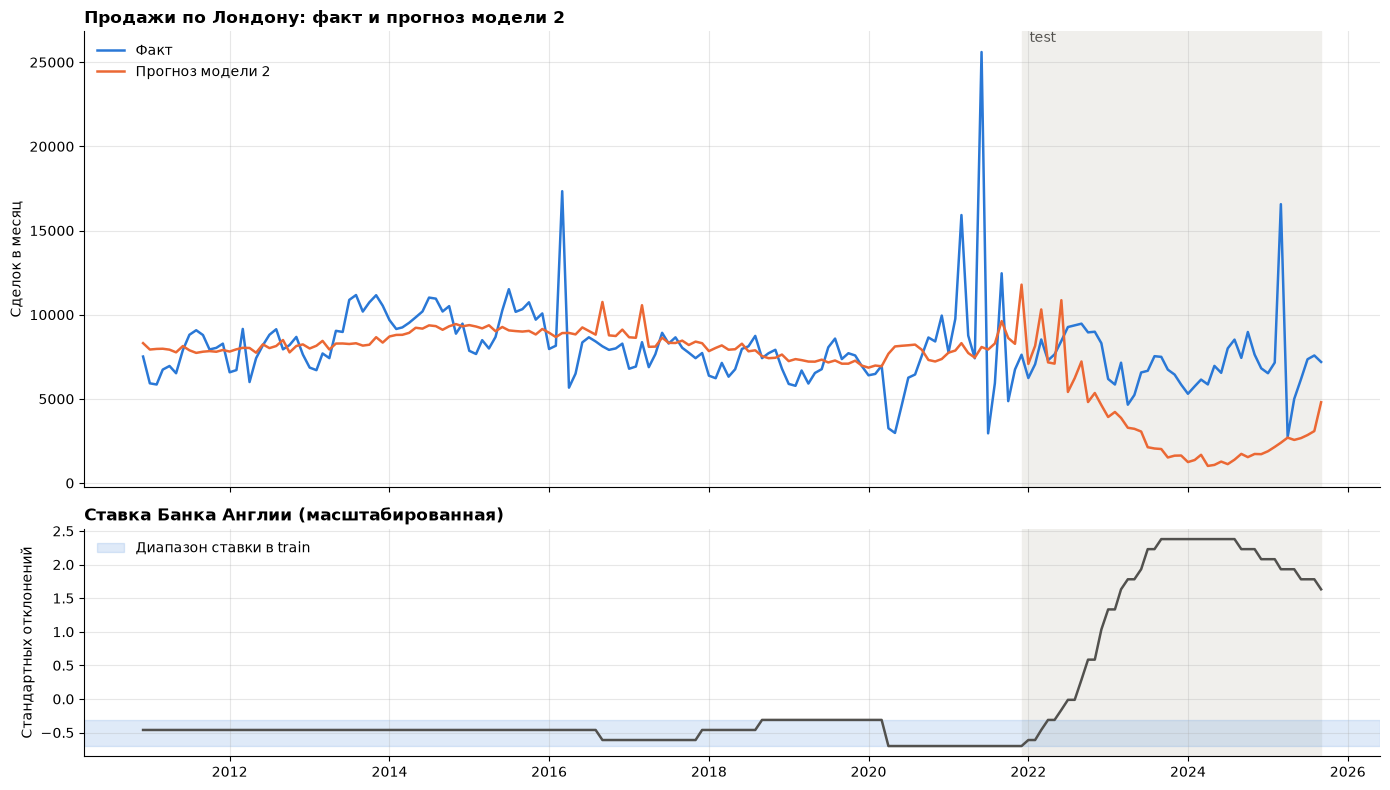

In [266]:
# Прогноз модели 2 по всем месяцам (первые 6 месяцев без лага пропускаем)
d = df.dropna(subset=lag6_cols)
plot_df = d[["month", "sales_count", "bank_rate"]].copy()
plot_df["pred"] = model_v2.predict(d[features_v2])

# Суммируем продажи по Лондону; ставка одинакова для всех районов, берём одно значение
monthly = plot_df.groupby("month").agg(
    sales_count=("sales_count", "sum"),
    pred=("pred", "sum"),
    bank_rate=("bank_rate", "first"),
)

rate_min, rate_max = train["bank_rate"].min(), train["bank_rate"].max()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, height_ratios=[2, 1])

for ax in (ax1, ax2):
    ax.axvspan(cutoff, monthly.index.max(), color="#f0efec", zorder=0)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

ax1.plot(monthly.index, monthly["sales_count"], color="#2a78d6", linewidth=1.8, label="Факт")
ax1.plot(monthly.index, monthly["pred"], color="#eb6834", linewidth=1.8, label="Прогноз модели 2")
ax1.text(cutoff, ax1.get_ylim()[1], "  test", va="top", color="#52514e")
ax1.set_title("Продажи по Лондону: факт и прогноз модели 2", loc="left", fontweight="bold")
ax1.set_ylabel("Сделок в месяц")
ax1.legend(loc="upper left", frameon=False)

ax2.axhspan(rate_min, rate_max, color="#2a78d6", alpha=0.15, label="Диапазон ставки в train")
ax2.plot(monthly.index, monthly["bank_rate"], color="#52514e", linewidth=1.8)
ax2.set_title("Ставка Банка Англии (масштабированная)", loc="left", fontweight="bold")
ax2.set_ylabel("Стандартных отклонений")
ax2.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.show()

In [267]:
features_v4 = [f for f in features_v2 if f != "bank_rate"]

X_train_v4, X_test_v4 = train[features_v4], test[features_v4]
y_train_v4, y_test_v4 = train["sales_count"], test["sales_count"]

In [268]:
model_v4 = LinearRegression()
model_v4.fit(X_train_v4, y_train_v4)

print("Коэффициенты:")
for feature, coef in zip(X_train_v4.columns, model_v4.coef_):
    print(f"  {feature:<40} {coef:>8.2f}")
print(f"  {'intercept':<40} {model_v4.intercept_:>8.2f}")

print("\nОшибки:")
for name, X, y in [("train", X_train_v4, y_train_v4), ("test", X_test_v4, y_test_v4)]:
    pred = model_v4.predict(X)
    print(
        f"  {name:<5}  MAE = {mean_absolute_error(y, pred):6.1f}   "
        f"RMSE = {root_mean_squared_error(y, pred):6.1f}   "
        f"R² = {r2_score(y, pred):.3f}"
    )

Коэффициенты:
  ptal                                        22.63
  crime_per_1000_lag2                        -23.56
  floor_area_median_epc_prev_year              8.49
  energy_efficiency_median_epc_prev_year      -5.44
  floor_height_median_epc_prev_year           -4.64
  mean_pay_prev_year                           0.55
  population_prev_2_years                      0.79
  sales_count_lag12                           23.87
  sales_count_lag6                            19.40
  borough_Barnet                             118.19
  borough_Bexley                              51.62
  borough_Brent                               28.05
  borough_Bromley                            146.35
  borough_Camden                              48.25
  borough_City of London                    -166.44
  borough_Croydon                            141.00
  borough_Ealing                              64.65
  borough_Enfield                             51.17
  borough_Greenwich                           90.1

### Вариант 5. Тест на последних 30 месяцах

Уменьшаем тестовый сет до последних 30 месяцев (апрель 2023 — сентябрь 2025), а тренировочный увеличиваем, чтобы модель увидела начало роста ставки в 2022–2023 годах.

- **5а** — признаки модели 2 (со ставкой);
- **5б** — признаки модели 4 (без ставки).
- **Вопрос:** перестанет ли ставка портить прогноз, если модель уже видела её рост?
- **Важно:** тестовый сет поменялся, поэтому MAE вариантов 5–8 нельзя напрямую сравнивать с вариантами 1–4. Сравниваем 5а и 5б между собой на одном разбиении.

In [269]:
n_test_months_v5 = 30
cutoff_v5 = months.iloc[-n_test_months_v5]  # первый месяц нового теста

train_v5 = df[df["month"] < cutoff_v5].dropna(subset=lag6_cols)
test_v5 = df[df["month"] >= cutoff_v5]

print(f"Train: {train_v5['month'].min():%Y-%m} — {train_v5['month'].max():%Y-%m}, {len(train_v5)} строк")
print(f"Test:  {test_v5['month'].min():%Y-%m} — {test_v5['month'].max():%Y-%m}, {len(test_v5)} строк")
print(f"bank_rate (scaled) в train: {train_v5['bank_rate'].min():.2f} — {train_v5['bank_rate'].max():.2f}")
print(f"bank_rate (scaled) в test:  {test_v5['bank_rate'].min():.2f} — {test_v5['bank_rate'].max():.2f}")

Train: 2010-12 — 2023-03, 4884 строк
Test:  2023-04 — 2025-09, 990 строк
bank_rate (scaled) в train: -0.70 — 1.63
bank_rate (scaled) в test:  1.63 — 2.38


In [270]:
X_train_v5a, X_test_v5a = train_v5[features_v2], test_v5[features_v2]
y_train_v5, y_test_v5 = train_v5["sales_count"], test_v5["sales_count"]

model_v5a = LinearRegression()
model_v5a.fit(X_train_v5a, y_train_v5)

print("Коэффициенты:")
for feature, coef in zip(X_train_v5a.columns, model_v5a.coef_):
    print(f"  {feature:<40} {coef:>8.2f}")
print(f"  {'intercept':<40} {model_v5a.intercept_:>8.2f}")

print("\nОшибки:")
for name, X, y in [("train", X_train_v5a, y_train_v5), ("test", X_test_v5a, y_test_v5)]:
    pred = model_v5a.predict(X)
    print(
        f"  {name:<5}  MAE = {mean_absolute_error(y, pred):6.1f}   "
        f"RMSE = {root_mean_squared_error(y, pred):6.1f}   "
        f"R² = {r2_score(y, pred):.3f}"
    )

Коэффициенты:
  ptal                                       -64.09
  crime_per_1000_lag2                        -19.18
  floor_area_median_epc_prev_year             15.33
  energy_efficiency_median_epc_prev_year      -5.05
  floor_height_median_epc_prev_year           -3.77
  bank_rate                                   -6.47
  mean_pay_prev_year                          -1.44
  population_prev_2_years                     -5.09
  sales_count_lag12                           12.56
  sales_count_lag6                            11.41
  borough_Barnet                             168.40
  borough_Bexley                              68.65
  borough_Brent                               71.67
  borough_Bromley                            183.26
  borough_Camden                             170.46
  borough_City of London                     296.10
  borough_Croydon                            200.44
  borough_Ealing                             118.13
  borough_Enfield                             70.1

In [271]:
X_train_v5b, X_test_v5b = train_v5[features_v4], test_v5[features_v4]

model_v5b = LinearRegression()
model_v5b.fit(X_train_v5b, y_train_v5)

print("Коэффициенты:")
for feature, coef in zip(X_train_v5b.columns, model_v5b.coef_):
    print(f"  {feature:<40} {coef:>8.2f}")
print(f"  {'intercept':<40} {model_v5b.intercept_:>8.2f}")

print("\nОшибки:")
for name, X, y in [("train", X_train_v5b, y_train_v5), ("test", X_test_v5b, y_test_v5)]:
    pred = model_v5b.predict(X)
    print(
        f"  {name:<5}  MAE = {mean_absolute_error(y, pred):6.1f}   "
        f"RMSE = {root_mean_squared_error(y, pred):6.1f}   "
        f"R² = {r2_score(y, pred):.3f}"
    )

Коэффициенты:
  ptal                                       -71.11
  crime_per_1000_lag2                        -20.51
  floor_area_median_epc_prev_year             14.82
  energy_efficiency_median_epc_prev_year      -6.29
  floor_height_median_epc_prev_year           -3.18
  mean_pay_prev_year                          -1.28
  population_prev_2_years                     -4.87
  sales_count_lag12                           12.59
  sales_count_lag6                            11.32
  borough_Barnet                             167.53
  borough_Bexley                              67.60
  borough_Brent                               72.30
  borough_Bromley                            181.83
  borough_Camden                             179.62
  borough_City of London                     335.89
  borough_Croydon                            199.99
  borough_Ealing                             118.39
  borough_Enfield                             68.24
  borough_Greenwich                          133.6

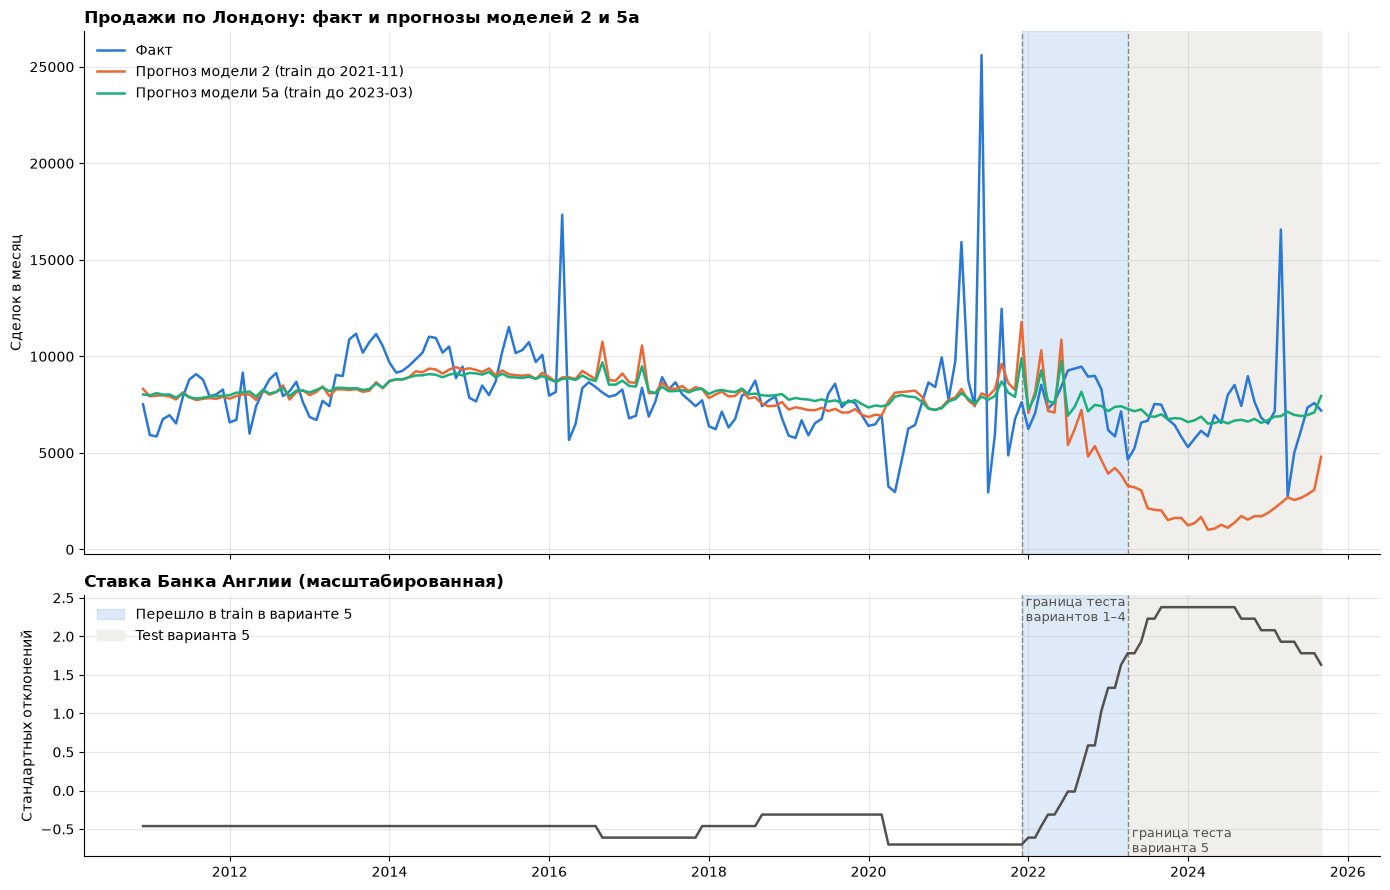

In [272]:
# Прогнозы моделей 2 и 5а по всем месяцам (первые 6 месяцев без лага пропускаем).
# Признаки у обеих одинаковые (со ставкой), отличается только период train.
d = df.dropna(subset=lag6_cols)
plot_df = d[["month", "sales_count", "bank_rate"]].copy()
plot_df["pred_v2"] = model_v2.predict(d[features_v2])
plot_df["pred_v5a"] = model_v5a.predict(d[features_v2])

# Суммируем по Лондону; ставка одинакова для всех районов, берём одно значение
monthly = plot_df.groupby("month").agg(
    sales_count=("sales_count", "sum"),
    pred_v2=("pred_v2", "sum"),
    pred_v5a=("pred_v5a", "sum"),
    bank_rate=("bank_rate", "first"),
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, height_ratios=[2, 1])

for ax in (ax1, ax2):
    # Месяцы, которые в варианте 5 перешли из теста в train, и новый тест
    ax.axvspan(cutoff, cutoff_v5, color="#2a78d6", alpha=0.15,
               label="Перешло в train в варианте 5" if ax is ax2 else None)
    ax.axvspan(cutoff_v5, monthly.index.max(), color="#f0efec",
               label="Test варианта 5" if ax is ax2 else None)
    ax.axvline(cutoff, color="#898781", linestyle="--", linewidth=1)
    ax.axvline(cutoff_v5, color="#898781", linestyle="--", linewidth=1)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

ax1.plot(monthly.index, monthly["sales_count"], color="#2a78d6", linewidth=1.8, label="Факт")
ax1.plot(monthly.index, monthly["pred_v2"], color="#eb6834", linewidth=1.8,
         label="Прогноз модели 2 (train до 2021-11)")
ax1.plot(monthly.index, monthly["pred_v5a"], color="#1baf7a", linewidth=1.8,
         label="Прогноз модели 5а (train до 2023-03)")
ax1.set_title("Продажи по Лондону: факт и прогнозы моделей 2 и 5а", loc="left", fontweight="bold")
ax1.set_ylabel("Сделок в месяц")
ax1.legend(loc="upper left", frameon=False)

ax2.plot(monthly.index, monthly["bank_rate"], color="#52514e", linewidth=1.8)
ax2.text(cutoff, ax2.get_ylim()[1], " граница теста\n вариантов 1–4", va="top", color="#52514e", fontsize=9)
ax2.text(cutoff_v5, ax2.get_ylim()[0], " граница теста\n варианта 5", va="bottom", color="#52514e", fontsize=9)
ax2.set_title("Ставка Банка Англии (масштабированная)", loc="left", fontweight="bold")
ax2.set_ylabel("Стандартных отклонений")
ax2.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.show()

### Вариант 6. Без транспортной доступности `ptal`

Берём модель 5а и убираем из неё только `ptal`.

- **Почему:** внутри района PTAL почти не меняется, поэтому при дамми районов он не несёт новой информации, а его единственный скачок в январе 2023 года связан со сменой источника данных TfL (подробнее ниже).
- **6а** — модель 5а без `ptal`, отличается от 5а ровно одним признаком;
- **6б** — 6а плюс `price_median_lag12`: ещё раз проверяем, нужен ли модели лаг цены.
- **Тест:** последние 30 месяцев, как в варианте 5, поэтому результаты можно сравнивать с 5а напрямую.

#### Почему убираем `ptal`: как в датасете считается транспортная доступность

PTAL (Public Transport Accessibility Level) — индекс TfL. Он считается из времени пешком до остановок и станций, частоты транспорта на них и среднего времени ожидания. В нашем датасете лежит непрерывный Accessibility Index, а не категории 0–6b.

TfL публикует PTAL не как временной ряд, а отдельными срезами. В датасете их два ([описание источника](../primary-data/loaders/tfl__ptal/README.md)):
- **до декабря 2022 года** — готовый показатель TfL по районам из релиза 2015 года (`av_ptai_2015`). Релиз рассчитан по данным 2008–2014 годов, и одно и то же значение стоит во всех месяцах с 2010 по 2022 год;
- **с января 2023 года** — релиз 2023 года. Готовых значений по районам TfL для него не публиковал, поэтому берётся простое среднее индекса по LSOA (небольшим статистическим участкам) района.

Переход был вынужденным, но два куска ряда несопоставимы. Скачок в январе 2023 года смешивает три разные вещи:
1. **разный способ усреднения по району** — в описании источника отмечено, что готовые значения 2015 года по районам не равны простому среднему по LSOA;
2. **реальные изменения за 8 лет между релизами** — новые линии (Elizabeth line, продление Northern line), но и сокращение автобусного обслуживания после пандемии. Эти изменения происходили постепенно, а в датасете все они «случаются» в один месяц;
3. **возможные правки методики TfL** между релизами.

Разделить эти эффекты по нашим данным нельзя. На графике видно, что у окраинных районов индекс вырос (Havering +120%, Bromley +94%), а у центральных упал (Westminster −21%, City of London −24%).

Для модели это значит: внутри района PTAL 12.5 лет постоянен и один раз скачет в январе 2023 года. При дамми районов он не несёт новой информации, а скачок модель может принять за эффект, который случился именно в этот месяц, как в варианте 5а, где коэффициент `ptal` стал −64.

Шкала на графике логарифмическая: так City of London (~90) не сжимает остальные районы (3–30), а одинаковое расстояние на графике означает одинаковое изменение в процентах.

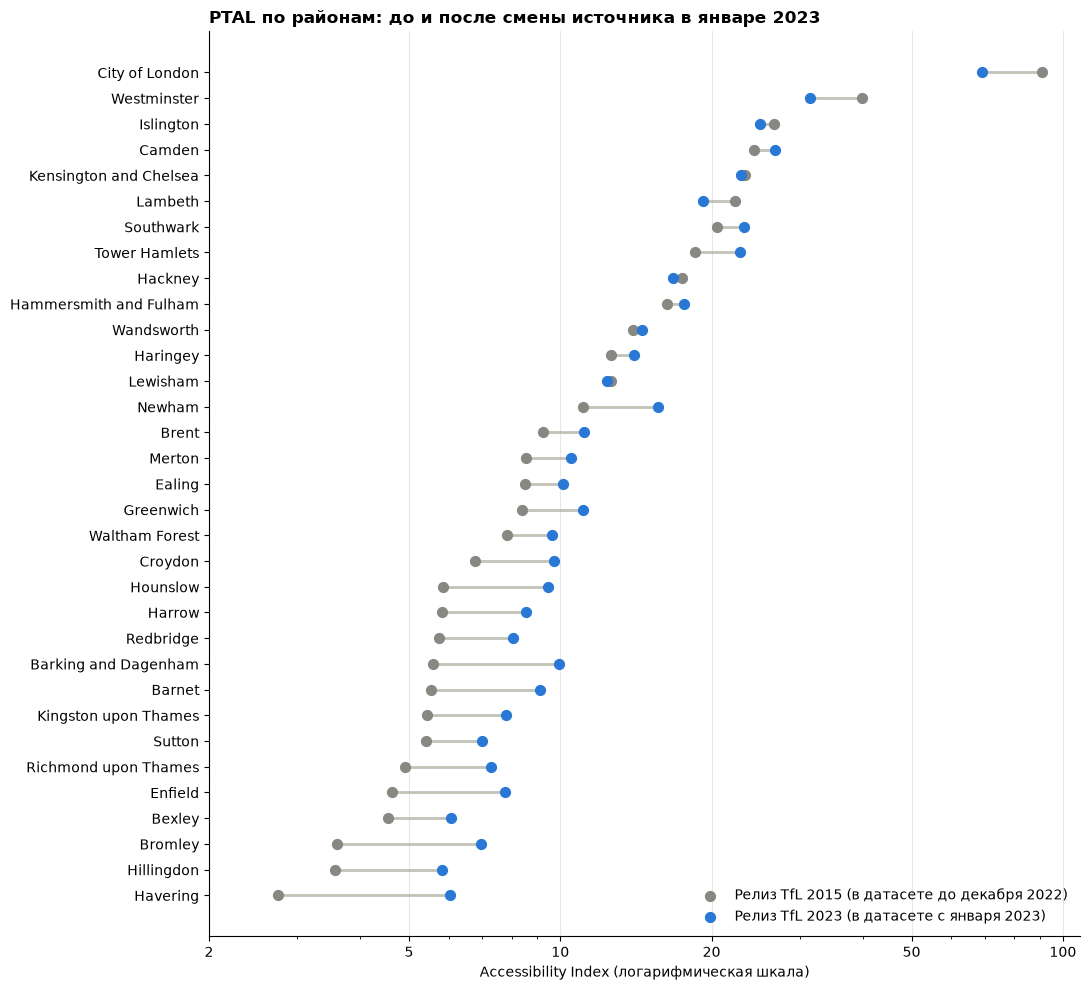

In [273]:
from matplotlib.ticker import NullFormatter, ScalarFormatter

# PTAL в исходных единицах берём из немасштабированного файла
df_raw = pd.read_csv("../dataset/data/borough-month-eda.csv", parse_dates=["month"])
year_raw = df_raw["month"].dt.year

# Внутри района до 2023 года одно значение и с 2023 года одно значение
ptal_change = pd.DataFrame({
    "до 2023": df_raw[year_raw == 2022].groupby("borough")["ptal"].first(),
    "с 2023": df_raw[year_raw == 2023].groupby("borough")["ptal"].first(),
}).sort_values("до 2023")

y = range(len(ptal_change))

fig, ax = plt.subplots(figsize=(11, 10))
ax.hlines(y, ptal_change["до 2023"], ptal_change["с 2023"], color="#c3c2b7", linewidth=2, zorder=1)
ax.scatter(ptal_change["до 2023"], y, color="#898781", s=50, zorder=2,
           label="Релиз TfL 2015 (в датасете до декабря 2022)")
ax.scatter(ptal_change["с 2023"], y, color="#2a78d6", s=50, zorder=3,
           label="Релиз TfL 2023 (в датасете с января 2023)")

ax.set_yticks(list(y), ptal_change.index)
ax.set_xscale("log")
ax.set_xticks([2, 5, 10, 20, 50, 100])
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())

ax.set_title("PTAL по районам: до и после смены источника в январе 2023", loc="left", fontweight="bold")
ax.set_xlabel("Accessibility Index (логарифмическая шкала)")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)

plt.tight_layout()
plt.show()

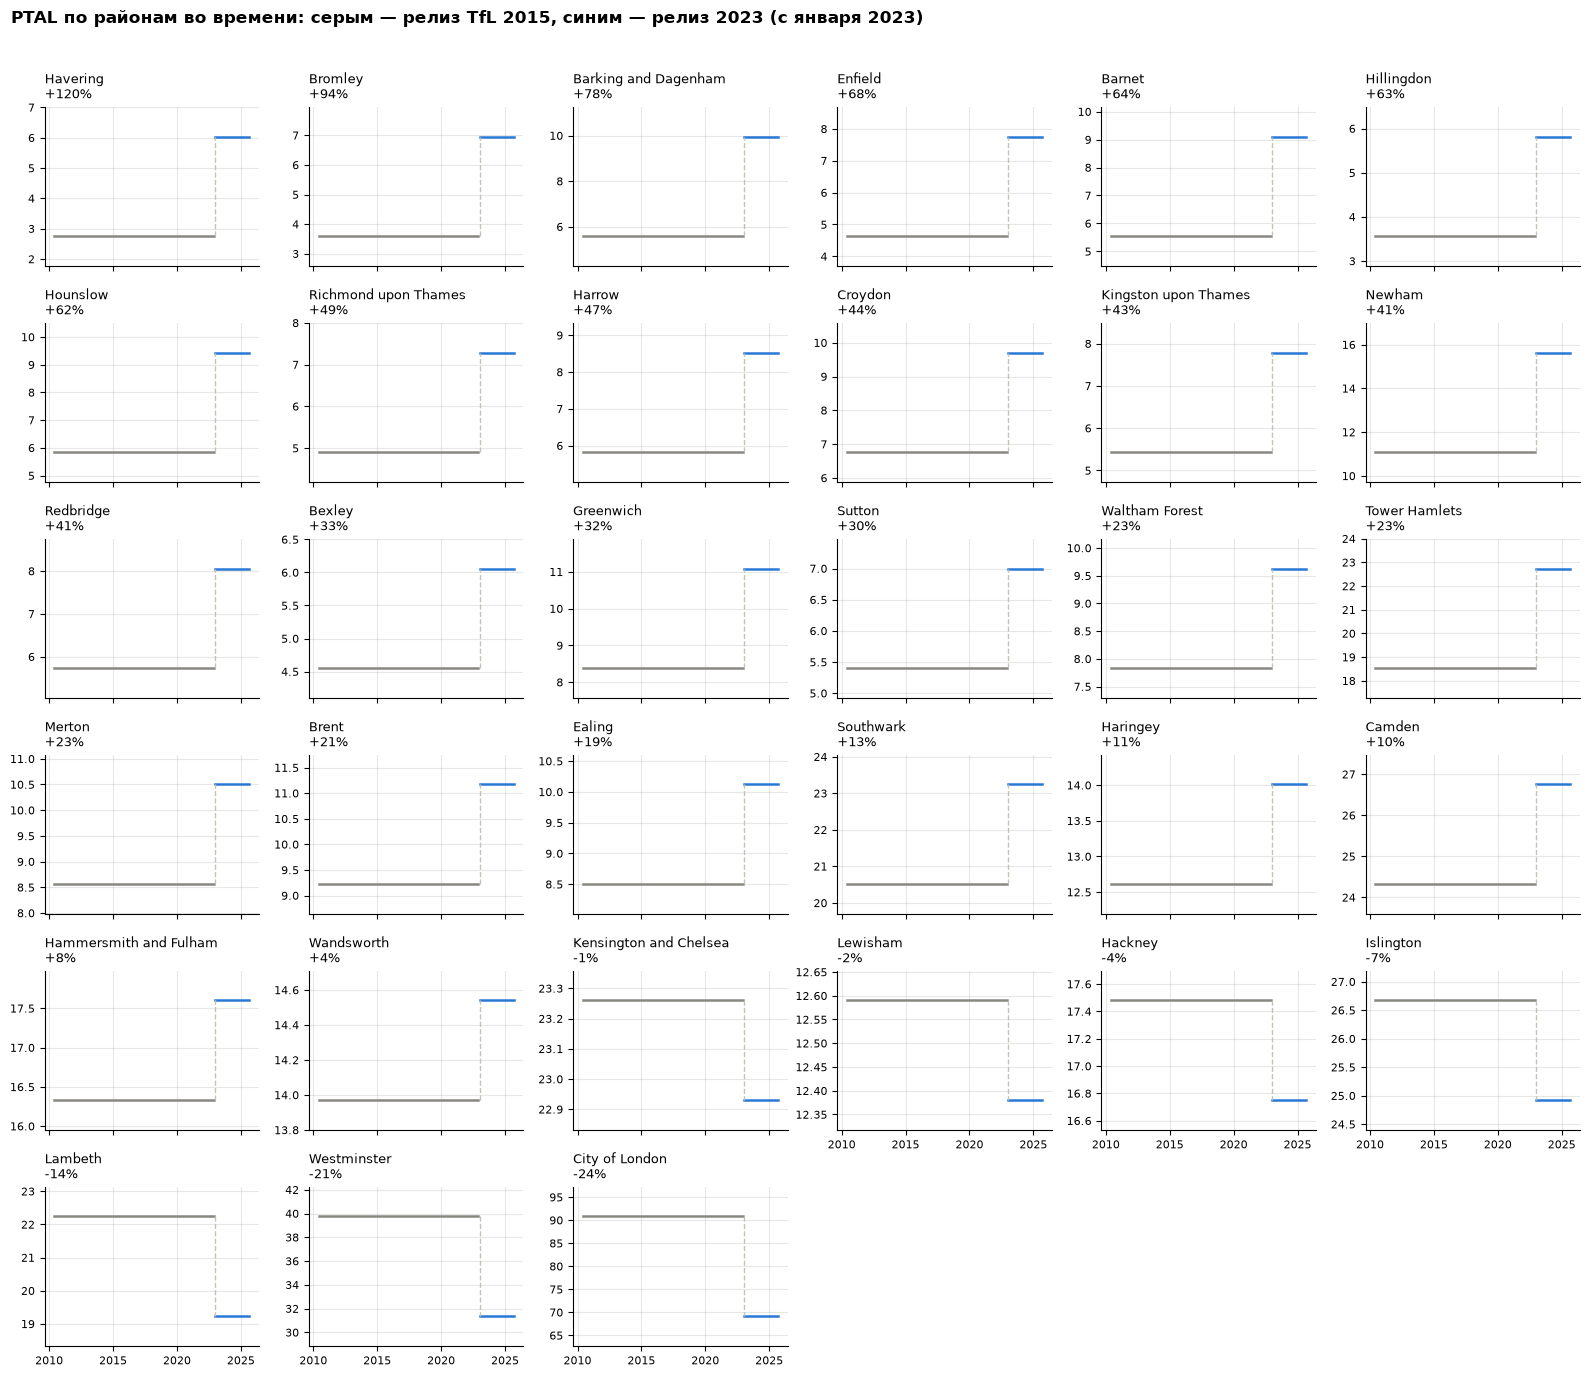

In [274]:
import matplotlib.dates as mdates

# PTAL по месяцам для каждого района (исходные единицы)
ptal_ts = df_raw.pivot(index="month", columns="borough", values="ptal")
switch = pd.Timestamp("2023-01-01")  # месяц смены источника TfL

# Порядок панелей: от самого большого роста к самому сильному падению
pct_change = (ptal_change["с 2023"] / ptal_change["до 2023"] - 1) * 100
order = pct_change.sort_values(ascending=False).index

fig, axes = plt.subplots(6, 6, figsize=(16, 14), sharex=True)

for ax, borough in zip(axes.flat, order):
    s = ptal_ts[borough]
    before, after = s[s.index < switch], s[s.index >= switch]
    ax.plot(before.index, before.values, color="#898781", linewidth=1.8)  # релиз 2015
    ax.plot(after.index, after.values, color="#2a78d6", linewidth=1.8)    # релиз 2023
    ax.vlines(switch, before.iloc[-1], after.iloc[0], color="#c3c2b7", linestyle="--", linewidth=1)
    ax.set_title(f"{borough}\n{pct_change[borough]:+.0f}%", fontsize=9, loc="left")
    ax.margins(y=0.3)
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

# 36 ячеек на 33 района: лишние прячем, а над ними включаем подписи оси X
for ax in axes.flat[len(order):]:
    ax.set_visible(False)
for ax in axes[-2, len(order) - 30:]:
    ax.tick_params(labelbottom=True)

fig.suptitle(
    "PTAL по районам во времени: серым — релиз TfL 2015, синим — релиз 2023 (с января 2023)",
    x=0.01, ha="left", fontweight="bold",
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [275]:
# Разбиение как в варианте 5; первые 6 месяцев без лага на 6 месяцев убираем
train_v6 = df[df["month"] < cutoff_v5].dropna(subset=lag6_cols)
test_v6 = df[df["month"] >= cutoff_v5]

# Признаки модели 5а без ptal
features_v6 = [f for f in features_v2 if f != "ptal"]

X_train_v6a, X_test_v6a = train_v6[features_v6], test_v6[features_v6]
y_train_v6, y_test_v6 = train_v6["sales_count"], test_v6["sales_count"]

print(f"Train: {train_v6['month'].min():%Y-%m} — {train_v6['month'].max():%Y-%m}, {len(train_v6)} строк")
print(f"Test:  {test_v6['month'].min():%Y-%m} — {test_v6['month'].max():%Y-%m}, {len(test_v6)} строк")

Train: 2010-12 — 2023-03, 4884 строк
Test:  2023-04 — 2025-09, 990 строк


In [276]:
model_v6a = LinearRegression()
model_v6a.fit(X_train_v6a, y_train_v6)

print("Коэффициенты:")
for feature, coef in zip(X_train_v6a.columns, model_v6a.coef_):
    print(f"  {feature:<40} {coef:>8.2f}")
print(f"  {'intercept':<40} {model_v6a.intercept_:>8.2f}")

print("\nОшибки:")
for name, X, y in [("train", X_train_v6a, y_train_v6), ("test", X_test_v6a, y_test_v6)]:
    pred = model_v6a.predict(X)
    print(
        f"  {name:<5}  MAE = {mean_absolute_error(y, pred):6.1f}   "
        f"RMSE = {root_mean_squared_error(y, pred):6.1f}   "
        f"R² = {r2_score(y, pred):.3f}"
    )

Коэффициенты:
  crime_per_1000_lag2                        -18.12
  floor_area_median_epc_prev_year             15.17
  energy_efficiency_median_epc_prev_year      -5.43
  floor_height_median_epc_prev_year           -3.98
  bank_rate                                   -7.72
  mean_pay_prev_year                          -1.63
  population_prev_2_years                     -4.97
  sales_count_lag12                           12.61
  sales_count_lag6                            11.36
  borough_Barnet                             169.26
  borough_Bexley                              73.83
  borough_Brent                               56.86
  borough_Bromley                            192.31
  borough_Camden                              91.31
  borough_City of London                     -58.24
  borough_Croydon                            195.61
  borough_Ealing                             106.43
  borough_Enfield                             74.37
  borough_Greenwich                          120.4

In [277]:
features_v6b = features_v6 + ["price_median_lag12"]
X_train_v6b, X_test_v6b = train_v6[features_v6b], test_v6[features_v6b]

model_v6b = LinearRegression()
model_v6b.fit(X_train_v6b, y_train_v6)

print("Коэффициенты:")
for feature, coef in zip(X_train_v6b.columns, model_v6b.coef_):
    print(f"  {feature:<40} {coef:>8.2f}")
print(f"  {'intercept':<40} {model_v6b.intercept_:>8.2f}")

print("\nОшибки:")
for name, X, y in [("train", X_train_v6b, y_train_v6), ("test", X_test_v6b, y_test_v6)]:
    pred = model_v6b.predict(X)
    print(
        f"  {name:<5}  MAE = {mean_absolute_error(y, pred):6.1f}   "
        f"RMSE = {root_mean_squared_error(y, pred):6.1f}   "
        f"R² = {r2_score(y, pred):.3f}"
    )

Коэффициенты:
  crime_per_1000_lag2                        -15.34
  floor_area_median_epc_prev_year             18.06
  energy_efficiency_median_epc_prev_year       1.15
  floor_height_median_epc_prev_year           -5.41
  bank_rate                                   -7.70
  mean_pay_prev_year                           0.31
  population_prev_2_years                     21.91
  sales_count_lag12                           12.32
  sales_count_lag6                            10.23
  borough_Barnet                             124.84
  borough_Bexley                              64.81
  borough_Brent                               26.66
  borough_Bromley                            159.65
  borough_Camden                             118.46
  borough_City of London                      45.96
  borough_Croydon                            141.12
  borough_Ealing                              66.53
  borough_Enfield                             42.37
  borough_Greenwich                           96.6

### Вариант 7. Сезонность

Добавляем к модели 6а сезонность через дамми-переменные месяцев.

- **Почему не числом:** номер месяца нельзя подавать числом от 1 до 12 — тогда линейная регрессия будет считать декабрь «в 12 раз больше» января.
- **Как:** 11 столбцов, базовый месяц — январь. Коэффициент месяца показывает, на сколько сделок в нём больше или меньше, чем в январе, при прочих равных.
- **Почему здесь нет экстраполяции, как со ставкой:** сезонность — тоже общий для всех районов признак, но каждый календарный месяц встречается в train 12–13 раз, а номер месяца всегда известен заранее.
- **Тест:** последние 30 месяцев, сравниваем с моделью 6а.

In [278]:
# Дамми месяцев: 12 месяцев -> 11 столбцов, базовый месяц — январь
month_dummies = pd.get_dummies(df["month_num"], prefix="month", drop_first=True, dtype=int)
df[month_dummies.columns] = month_dummies

# Разбиение как в вариантах 5 и 6; пересобираем, чтобы в train/test попали новые столбцы
train_v7 = df[df["month"] < cutoff_v5].dropna(subset=lag6_cols)
test_v7 = df[df["month"] >= cutoff_v5]

features_v7 = features_v6 + month_dummies.columns.tolist()

X_train_v7, X_test_v7 = train_v7[features_v7], test_v7[features_v7]
y_train_v7, y_test_v7 = train_v7["sales_count"], test_v7["sales_count"]

print(f"Train: {train_v7['month'].min():%Y-%m} — {train_v7['month'].max():%Y-%m}, {len(train_v7)} строк")
print(f"Test:  {test_v7['month'].min():%Y-%m} — {test_v7['month'].max():%Y-%m}, {len(test_v7)} строк")

Train: 2010-12 — 2023-03, 4884 строк
Test:  2023-04 — 2025-09, 990 строк


In [279]:
model_v7 = LinearRegression()
model_v7.fit(X_train_v7, y_train_v7)

print("Коэффициенты:")
for feature, coef in zip(X_train_v7.columns, model_v7.coef_):
    print(f"  {feature:<40} {coef:>8.2f}")
print(f"  {'intercept':<40} {model_v7.intercept_:>8.2f}")

print("\nОшибки:")
for name, X, y in [("train", X_train_v7, y_train_v7), ("test", X_test_v7, y_test_v7)]:
    pred = model_v7.predict(X)
    print(
        f"  {name:<5}  MAE = {mean_absolute_error(y, pred):6.1f}   "
        f"RMSE = {root_mean_squared_error(y, pred):6.1f}   "
        f"R² = {r2_score(y, pred):.3f}"
    )

Коэффициенты:
  crime_per_1000_lag2                        -22.47
  floor_area_median_epc_prev_year             18.04
  energy_efficiency_median_epc_prev_year      -4.07
  floor_height_median_epc_prev_year           -4.32
  bank_rate                                   -6.88
  mean_pay_prev_year                          -2.01
  population_prev_2_years                     -5.58
  sales_count_lag12                           -0.97
  sales_count_lag6                            15.79
  borough_Barnet                             184.69
  borough_Bexley                              79.01
  borough_Brent                               62.69
  borough_Bromley                            209.51
  borough_Camden                             105.42
  borough_City of London                     -64.86
  borough_Croydon                            214.86
  borough_Ealing                             116.66
  borough_Enfield                             82.32
  borough_Greenwich                          129.5

#### Значимость коэффициентов модели 7

Для каждого коэффициента проверяем гипотезу H₀: «коэффициент равен нулю», то есть признак не влияет на продажи при прочих равных. Статистика t = коэффициент / стандартная ошибка (SE), по ней считаем p-value. Если p < 0.05, отвергаем H₀ на уровне 5%.

Считаем два варианта стандартных ошибок:
- **классические** — предполагают, что все 4884 строки независимы и разброс ошибок у всех одинаковый;
- **кластеризованные по району и по месяцу** — допускают, что ошибки связаны внутри района (соседние месяцы похожи) и внутри месяца (общие шоки вроде всплесков SDLT бьют по всем районам сразу).

У нас панельные данные, и предпосылки классического теста не выполняются, поэтому выводы делаем по кластеризованным p-value. Ставка и дамми месяцев одинаковы для всех районов, поэтому независимой информации о них в данных столько, сколько месяцев, а не строк. Классический тест этого не учитывает и сильно переоценивает точность.

Две оговорки:
- коэффициенты дамми сравнивают каждый район с базовым (Barking and Dagenham), а каждый месяц — с январём;
- значимость коэффициента — это не то же самое, что польза признака для прогноза. Её мы проверяем по MAE на тесте.

In [280]:
from scipy import stats

# Матрица признаков модели 7 с константой (для свободного члена) и остатки на train
X = np.column_stack([np.ones(len(X_train_v7)), X_train_v7.to_numpy(dtype=float)])
y = y_train_v7.to_numpy(dtype=float)
beta = np.concatenate([[model_v7.intercept_], model_v7.coef_])
resid = y - X @ beta
n, k = X.shape
XtX_inv = np.linalg.inv(X.T @ X)

# 1. Классические стандартные ошибки: все строки независимы, разброс ошибок одинаковый
sigma2 = resid @ resid / (n - k)
se_classic = np.sqrt(np.diag(sigma2 * XtX_inv))
p_classic = 2 * stats.t.sf(np.abs(beta / se_classic), df=n - k)

# 2. Кластеризованные стандартные ошибки (по району и по месяцу): ошибки могут быть
#    связаны внутри района (соседние месяцы) и внутри месяца (общие шоки для всех районов)
def cluster_cov(groups):
    meat = np.zeros((k, k))
    for g in np.unique(groups):
        mask = groups == g
        s = X[mask].T @ resid[mask]
        meat += np.outer(s, s)
    return XtX_inv @ meat @ XtX_inv

cov_borough = cluster_cov(train_v7["borough"].to_numpy())
cov_month = cluster_cov(train_v7["month"].to_numpy())
cov_row = XtX_inv @ (X.T * resid**2) @ X @ XtX_inv  # каждая строка — свой кластер
se_cluster = np.sqrt(np.diag(cov_borough + cov_month - cov_row))

# Степени свободы: число кластеров минус 1 (районов 33 — меньше, чем месяцев)
n_clusters = min(train_v7["borough"].nunique(), train_v7["month"].nunique())
p_cluster = 2 * stats.t.sf(np.abs(beta / se_cluster), df=n_clusters - 1)

significance = pd.DataFrame(
    {
        "коэффициент": beta,
        "SE классич.": se_classic,
        "p классич.": p_classic,
        "SE кластер.": se_cluster,
        "p кластер.": p_cluster,
        "значим (кластер., 5%)": p_cluster < 0.05,
    },
    index=["intercept"] + X_train_v7.columns.tolist(),
)
significance.round(3)

,коэффициент,SE классич.,p классич.,SE кластер.,p кластер.,"значим (кластер., 5%)"
intercept,101.704,10.018,0.000,18.631,0.000,True
crime_per_1000_lag2,-22.466,3.525,0.000,14.659,0.135,False
floor_area_median_epc_prev_year,18.040,2.708,0.000,6.639,0.011,True
energy_efficiency_median_epc_prev_year,-4.074,2.697,0.131,5.286,0.447,False
floor_height_median_epc_prev_year,-4.320,2.332,0.064,4.387,0.332,False
bank_rate,-6.882,3.464,0.047,14.331,0.634,False
mean_pay_prev_year,-2.011,2.206,0.362,2.372,0.403,False
population_prev_2_years,-5.578,8.908,0.531,29.094,0.849,False
sales_count_lag12,-0.972,1.617,0.548,10.938,0.930,False
sales_count_lag6,15.794,1.532,0.000,9.312,0.100,False


### Вариант 8. Флаги изменений налога SDLT

Добавляем к модели 7 флаги изменений налога на покупку жилья (Stamp Duty Land Tax).

- **Зачем:** в EDA мы выяснили, что самые большие всплески продаж — это месяцы перед ужесточением налога. Покупатели спешат завершить сделку по старым правилам, а в следующем месяце сделок резко меньше. Налог считается по дате завершения сделки, как и `sales_count` у Land Registry, поэтому всплеск приходится ровно на последний месяц перед изменением.
- **Утечки нет:** изменения налога объявлялись заранее, поэтому на дату прогноза флаги известны.
- **Тест:** последние 30 месяцев, сравниваем с моделью 7.

**Изменения налога** (даты сверены с GOV.UK):

| Что менялось | Последний месяц по старым правилам (`sdlt_deadline`) | Первый месяц по новым (`sdlt_after`) | Когда стало известно | Источник |
|---|---|---|---|---|
| С 1 апреля 2016: +3 п.п. для второго жилья и покупок под сдачу | март 2016 | апрель 2016 | ноябрь 2015 (Autumn Statement) | [GOV.UK](https://www.gov.uk/government/publications/stamp-duty-land-tax-higher-rates-on-purchases-of-additional-residential-properties/stamp-duty-land-tax-higher-rates-on-purchases-of-additional-residential-properties) |
| 31 марта 2021: конец налоговых каникул по исходному закону | март 2021 | — | июль 2020 (закон о каникулах) | [legislation.gov.uk](https://www.legislation.gov.uk/ukpga/2020/15/enacted) |
| С 1 июля 2021: необлагаемый порог £500 000 → £250 000 | июнь 2021 | июль 2021 | март 2021 (Budget 2021) | [GOV.UK](https://www.gov.uk/government/publications/extension-of-the-temporary-increase-to-the-stamp-duty-land-tax-nil-rate-band-for-residential-properties/extension-of-the-temporary-increase-to-the-stamp-duty-land-tax-nil-rate-band-for-residential-properties) |
| С 1 октября 2021: порог £250 000 → £125 000 | сентябрь 2021 | октябрь 2021 | март 2021 (Budget 2021) | [GOV.UK](https://www.gov.uk/guidance/stamp-duty-land-tax-temporary-reduced-rates) |
| С 1 апреля 2025: пороги возвращаются (£250 000 → £125 000, для первых покупателей £425 000 → £300 000) | март 2025 | апрель 2025 | конец льготы закреплён законом в 2023 году | [GOV.UK](https://www.gov.uk/government/statistics/quarterly-stamp-duty-land-tax-sdlt-statistics/quarterly-stamp-duty-land-tax-sdlt-statistics-commentary) |

**Особые случаи:**
- у марта 2021 года нет флага `sdlt_after`: 3 марта 2021 года каникулы продлили, и к прогнозу на апрель уже было известно, что налог не вырастет;
- изменения 23 сентября 2022 года (снижение налога) и 31 октября 2024 года (надбавка за второе жильё 3% → 5%) вступили в силу сразу после объявления, спешить было некогда, поэтому флагов для них нет.

**Эхо-флаги для лага.** Через полгода после всплеска он «приезжает» в `sales_count_lag6`, и модель ждёт повторения, которого не будет. Флаги `sdlt_deadline_lag6` и `sdlt_after_lag6` помечают такие месяцы.

In [281]:
# Последний месяц перед ужесточением налога: покупатели спешат завершить сделку
sdlt_deadlines = pd.to_datetime(["2016-03-01", "2021-03-01", "2021-06-01", "2021-09-01", "2025-03-01"])
# Первый месяц после ужесточения: сделок резко меньше
sdlt_after_months = pd.to_datetime(["2016-04-01", "2021-07-01", "2021-10-01", "2025-04-01"])

df["sdlt_deadline"] = df["month"].isin(sdlt_deadlines).astype(int)
df["sdlt_after"] = df["month"].isin(sdlt_after_months).astype(int)

# Через 6 месяцев всплеск или провал попадает в sales_count_lag6.
# Помечаем такие месяцы, чтобы модель не ждала повторения
df["sdlt_deadline_lag6"] = df["month"].isin(sdlt_deadlines + pd.DateOffset(months=6)).astype(int)
df["sdlt_after_lag6"] = df["month"].isin(sdlt_after_months + pd.DateOffset(months=6)).astype(int)

sdlt_cols = ["sdlt_deadline", "sdlt_after", "sdlt_deadline_lag6", "sdlt_after_lag6"]

# Разбиение как в вариантах 5–7; пересобираем, чтобы в train/test попали новые столбцы
train_v8 = df[df["month"] < cutoff_v5].dropna(subset=lag6_cols)
test_v8 = df[df["month"] >= cutoff_v5]

features_v8 = features_v7 + sdlt_cols

X_train_v8, X_test_v8 = train_v8[features_v8], test_v8[features_v8]
y_train_v8, y_test_v8 = train_v8["sales_count"], test_v8["sales_count"]

# Проверка: какие месяцы помечены каждым флагом в train и в test
for col in sdlt_cols:
    train_months = train_v8.loc[train_v8[col] == 1, "month"].dt.strftime("%Y-%m").unique()
    test_months = test_v8.loc[test_v8[col] == 1, "month"].dt.strftime("%Y-%m").unique()
    print(f"{col:<20} train: {', '.join(train_months):<36} test: {', '.join(test_months) or '—'}")

sdlt_deadline        train: 2016-03, 2021-03, 2021-06, 2021-09   test: 2025-03
sdlt_after           train: 2016-04, 2021-07, 2021-10            test: 2025-04
sdlt_deadline_lag6   train: 2016-09, 2021-09, 2021-12, 2022-03   test: 2025-09
sdlt_after_lag6      train: 2016-10, 2022-01, 2022-04            test: —


In [282]:
model_v8 = LinearRegression()
model_v8.fit(X_train_v8, y_train_v8)

print("Коэффициенты:")
for feature, coef in zip(X_train_v8.columns, model_v8.coef_):
    print(f"  {feature:<40} {coef:>8.2f}")
print(f"  {'intercept':<40} {model_v8.intercept_:>8.2f}")

print("\nОшибки:")
for name, X, y in [("train", X_train_v8, y_train_v8), ("test", X_test_v8, y_test_v8)]:
    pred = model_v8.predict(X)
    print(
        f"  {name:<5}  MAE = {mean_absolute_error(y, pred):6.1f}   "
        f"RMSE = {root_mean_squared_error(y, pred):6.1f}   "
        f"R² = {r2_score(y, pred):.3f}"
    )

Коэффициенты:
  crime_per_1000_lag2                         -8.68
  floor_area_median_epc_prev_year             16.72
  energy_efficiency_median_epc_prev_year      -4.93
  floor_height_median_epc_prev_year           -2.77
  bank_rate                                    2.87
  mean_pay_prev_year                          -2.78
  population_prev_2_years                    -22.06
  sales_count_lag12                           12.37
  sales_count_lag6                            19.92
  borough_Barnet                             195.40
  borough_Bexley                              79.87
  borough_Brent                               82.92
  borough_Bromley                            202.14
  borough_Camden                              81.88
  borough_City of London                     -89.03
  borough_Croydon                            218.59
  borough_Ealing                             133.60
  borough_Enfield                             96.54
  borough_Greenwich                          125.4

## Итоговые результаты

Собираем метрики всех вариантов в одну таблицу. Для каждого теста добавляем **бейзлайн** (вариант 0) — прогноз «продажи такие же, как год назад», без всякой модели. Модель имеет смысл, только если она его обгоняет.

Как читать таблицу:
- **Тест** — на каком разбиении считались метрики. Сравнивать можно только строки с одинаковым тестом;
- **Сравниваем с** — от какого варианта отталкивались; **Δ test MAE** — как изменилась ошибка на тесте по сравнению с ним (минус — стало лучше);
- **test MAE, % от среднего** — ошибка в процентах от средних продаж на тесте;
- **★** — лучший вариант на своём тесте.

In [283]:
def scores(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
    }


def make_row(test_name, name, change, compare_with, n_features, y_tr, pred_tr, y_te, pred_te):
    tr, te = scores(y_tr, pred_tr), scores(y_te, pred_te)
    return {
        "Тест": test_name,
        "Вариант": name,
        "Что меняем": change,
        "Сравниваем с": compare_with,
        "Признаков": n_features,
        "Строк train": len(y_tr),
        "train MAE": tr["MAE"],
        "train RMSE": tr["RMSE"],
        "train R²": tr["R²"],
        "test MAE": te["MAE"],
        "test MAE, % от среднего": te["MAE"] / y_te.mean() * 100,
        "test RMSE": te["RMSE"],
        "test R²": te["R²"],
    }


# Бейзлайн «продажи как год назад»: продажи того же района 12 месяцев назад, в сделках
df["naive_lag12"] = df.groupby("borough")["sales_count"].shift(12)

TEST_A = "A: 46 мес (2021-12 — 2025-09)"
TEST_B = "B: 30 мес (2023-04 — 2025-09)"

# (вариант, что меняем, с каким вариантом сравниваем, модель, X_train, y_train, X_test, y_test)
models_by_test = {
    TEST_A: (cutoff, [
        ("1", "8 числовых признаков", "0", model, X_train, y_train, X_test, y_test),
        ("2", "+ дамми районов, лаги продаж", "1", model_v2, X_train_v2, y_train_v2, X_test_v2, y_test_v2),
        ("3", "2 + лаги цены", "2", model_v3, X_train_v3, y_train_v3, X_test_v3, y_test_v3),
        ("4", "2 без bank_rate", "2", model_v4, X_train_v4, y_train_v4, X_test_v4, y_test_v4),
    ]),
    TEST_B: (cutoff_v5, [
        ("5а", "признаки модели 2", "0", model_v5a, X_train_v5a, y_train_v5, X_test_v5a, y_test_v5),
        ("5б", "признаки модели 4 (без bank_rate)", "5а", model_v5b, X_train_v5b, y_train_v5, X_test_v5b, y_test_v5),
        ("6а", "5а без ptal", "5а", model_v6a, X_train_v6a, y_train_v6, X_test_v6a, y_test_v6),
        ("6б", "6а + лаг цены на 12 мес.", "6а", model_v6b, X_train_v6b, y_train_v6, X_test_v6b, y_test_v6),
        ("7", "6а + сезонность", "6а", model_v7, X_train_v7, y_train_v7, X_test_v7, y_test_v7),
        ("8", "7 + флаги SDLT", "7", model_v8, X_train_v8, y_train_v8, X_test_v8, y_test_v8),
    ]),
}

rows = []
for test_name, (cutoff_month, models) in models_by_test.items():
    # Бейзлайн на том же разбиении (в train — месяцы, для которых есть значение год назад)
    tr = df[df["month"] < cutoff_month].dropna(subset=["naive_lag12"])
    te = df[df["month"] >= cutoff_month]
    rows.append(make_row(test_name, "0", "бейзлайн: как год назад", None, 0,
                         tr["sales_count"], tr["naive_lag12"], te["sales_count"], te["naive_lag12"]))
    for name, change, compare_with, m, X_tr, y_tr, X_te, y_te in models:
        rows.append(make_row(test_name, name, change, compare_with, X_tr.shape[1],
                             y_tr, m.predict(X_tr), y_te, m.predict(X_te)))

results = pd.DataFrame(rows)

# Насколько изменилась ошибка на тесте по сравнению с вариантом, от которого отталкивались
test_mae = results.set_index(["Тест", "Вариант"])["test MAE"]
results["Δ test MAE"] = [
    mae - test_mae[(test_name, base)] if pd.notna(base) else np.nan
    for test_name, base, mae in zip(results["Тест"], results["Сравниваем с"], results["test MAE"])
]

# Лучший вариант на каждом тесте
results["Лучший"] = results["test MAE"] == results.groupby("Тест")["test MAE"].transform("min")

# Таблица для показа: округляем и приводим к удобному виду
results_view = results.copy()
for col in ["train MAE", "train RMSE", "test MAE", "test RMSE"]:
    results_view[col] = results_view[col].map("{:.1f}".format)
for col in ["train R²", "test R²"]:
    results_view[col] = results_view[col].map("{:.3f}".format)
results_view["test MAE, % от среднего"] = results_view["test MAE, % от среднего"].map("{:.1f}%".format)
results_view["Δ test MAE"] = results_view["Δ test MAE"].map(lambda x: "—" if pd.isna(x) else f"{x:+.1f}")
results_view["Сравниваем с"] = results_view["Сравниваем с"].fillna("—")
results_view["Лучший"] = results_view["Лучший"].map({True: "★", False: ""})

results_view.set_index(["Тест", "Вариант"])

Что меняем  \
Тест                          Вариант                                      
A: 46 мес (2021-12 — 2025-09) 0                  бейзлайн: как год назад   
                              1                     8 числовых признаков   
                              2             + дамми районов, лаги продаж   
                              3                            2 + лаги цены   
                              4                          2 без bank_rate   
B: 30 мес (2023-04 — 2025-09) 0                  бейзлайн: как год назад   
                              5а                       признаки модели 2   
                              5б       признаки модели 4 (без bank_rate)   
                              6а                             5а без ptal   
                              6б                6а + лаг цены на 12 мес.   
                              7                          6а + сезонность   
                              8                           7 + флаги SDLT   

                                      Сравниваем с  Признаков  Строк train  \
Тест                          Вариант                                        
A: 46 мес (2021-12 — 2025-09) 0                  —          0         4158   
                              1                  0          8         4554   
                              2                  1         42         4356   
                              3                  2         44         4356   
                              4                  2         41         4356   
B: 30 мес (2023-04 — 2025-09) 0                  —          0         4686   
                              5а                 0         42         4884   
                              5б                5а         41         4884   
                              6а                5а         41         4884   
                              6б                6а         42         4884   
                              7                 6а         52         4884   
                              8                  7         56         4884   

                                      train MAE train RMSE train R² test MAE  \
Тест                          Вариант                                          
A: 46 мес (2021-12 — 2025-09) 0            59.2      100.0    0.321     76.5   
                              1            68.4       98.3    0.315     67.9   
                              2            51.7       83.5    0.516    123.6   
                              3            50.9       83.1    0.521    144.2   
                              4            51.7       83.8    0.513     55.2   
B: 30 мес (2023-04 — 2025-09) 0            64.9      111.6    0.117     58.7   
                              5а           51.3       81.5    0.519     48.0   
                              5б           51.2       81.5    0.519     50.3   
                              6а           51.3       81.6    0.519     48.2   
                              6б           50.7       81.2    0.523     49.6   
                              7            49.3       76.9    0.572     47.6   
                              8            41.6       58.7    0.751     40.2   

                                      test MAE, % от среднего test RMSE  \
Тест                          Вариант                                     
A: 46 мес (2021-12 — 2025-09) 0                         34.8%     126.6   
                              1                         30.9%      89.2   
                              2                         56.2%     146.0   
                              3                         65.6%     168.2   
                              4                         25.1%      78.4   
B: 30 мес (2023-04 — 2025-09) 0                         28.0%      87.5   
                              5а                        22.9%      77.2   
                              5б                        24.0%      78.5   
                              6а 

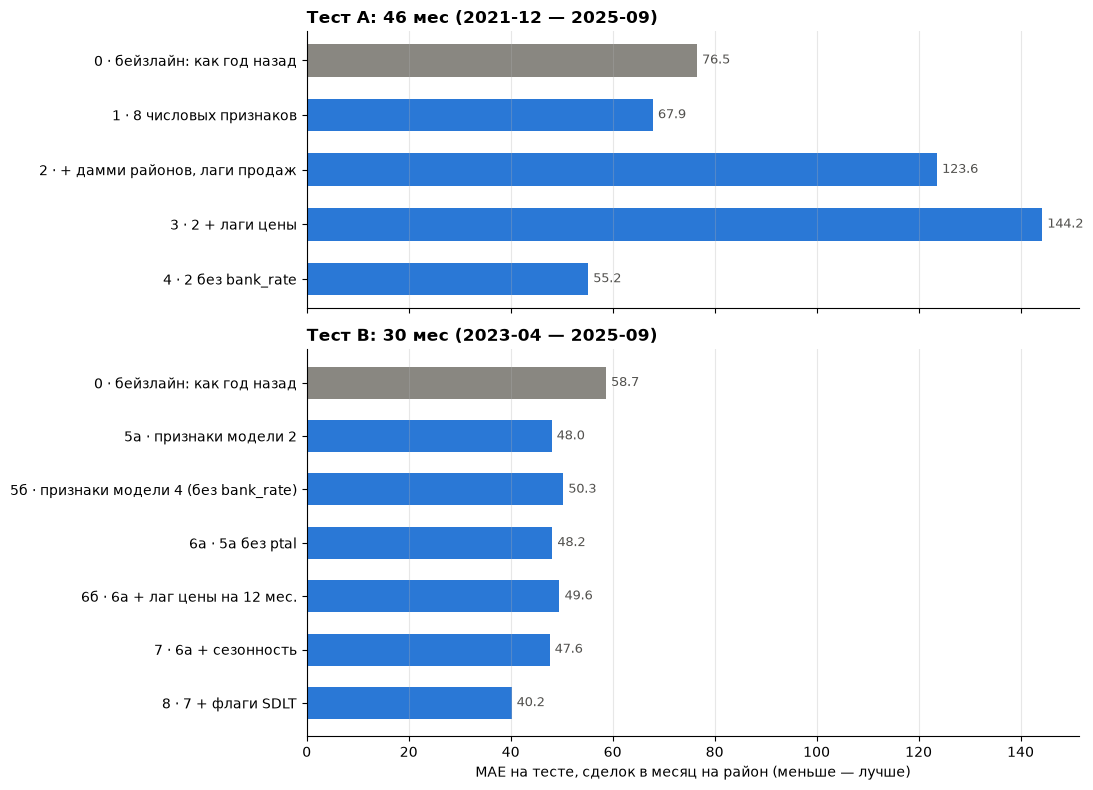

In [284]:
# Ошибка на тесте по вариантам: два графика, потому что тесты разные и сравнивать их между собой нельзя
fig, axes = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True,
    height_ratios=[(results["Тест"] == TEST_A).sum(), (results["Тест"] == TEST_B).sum()],
)

for ax, test_name in zip(axes, [TEST_A, TEST_B]):
    part = results[results["Тест"] == test_name].iloc[::-1]  # первый вариант — сверху
    labels = [f"{v} · {c}" for v, c in zip(part["Вариант"], part["Что меняем"])]
    colors = ["#898781" if v == "0" else "#2a78d6" for v in part["Вариант"]]  # бейзлайн — серым

    ax.barh(labels, part["test MAE"], color=colors, height=0.6)
    for y, value in enumerate(part["test MAE"]):
        ax.text(value + 1, y, f"{value:.1f}", va="center", color="#52514e", fontsize=9)

    ax.set_title(f"Тест {test_name}", loc="left", fontweight="bold")
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

axes[-1].set_xlabel("MAE на тесте, сделок в месяц на район (меньше — лучше)")
axes[-1].margins(x=0.08)
plt.tight_layout()
plt.show()

## Общий вывод

### Главный результат

Лучшая модель — **вариант 8**: линейная регрессия с дамми районов, лагами продаж на 6 и 12 месяцев, сезонностью и флагами изменений налога SDLT. На тесте (апрель 2023 — сентябрь 2025) она ошибается в среднем на **40.2 сделки в месяц на район** (19% от средних продаж), R² = **0.75**. Это почти на треть (31%) точнее бейзлайна «продажи как год назад» на том же тесте (MAE 58.7).

### Что показали эксперименты

1. **Признаки района сами по себе (вариант 1)** уже обгоняют бейзлайн (MAE 67.9 против 76.5), но объясняют мало (R² = 0.21 на тесте): в основном они отличают районы друг от друга, а не колебания продаж во времени.
2. **Дамми районов и лаги продаж (вариант 2)** заметно улучшили train (MAE 68.4 → 51.7), но на тесте модель сломалась (MAE 123.6). Причина — ставка Банка Англии: в train она почти не менялась (0.1–0.75%), в тесте выросла до 5.25%, и модель продлила выученный на узком диапазоне наклон. Без ставки (вариант 4) MAE упал до 55.2 — лучший результат на тесте A. Когда train захватил рост ставки (вариант 5), её коэффициент уменьшился с −62 до −6.5, и вред исчез.
3. **Лаги медианной цены не помогают** прогнозу количества сделок ни в одной постановке (варианты 3 и 6б): train почти не меняется, тест ухудшается, а коэффициенты признаков района «скачут» из-за мультиколлинеарности.
4. **PTAL — артефакт склейки двух релизов TfL.** При дамми районов он не несёт новой информации: без него качество то же (48.0 → 48.2), зато модель не опирается на ложный скачок в январе 2023 года.
5. **Сезонность** через дамми месяцев улучшила RMSE и R² (77.3 → 71.8, 0.42 → 0.50) и забрала на себя роль лага за год: его коэффициент почти обнулился.
6. **Флаги налога SDLT — самый сильный шаг:** MAE 47.6 → 40.2, R² 0.50 → 0.75. Модель начала ловить всплеск марта 2025 года и провал апреля. Важна деталь: без «эхо-флагов» для лага на 6 месяцев (проверяли отдельно) ошибка была даже выше, чем без флагов вообще.
7. **Тест значимости** показал, что на панельных данных классические p-value слишком оптимистичны. С кластеризованными ошибками незначимы ставка, лаг за год и медленные признаки района (население, зарплата, энергоэффективность, высота потолков).

### Уроки

- Признак, который на тесте выходит за пределы значений train, опасен для линейной модели: она продолжает прямую туда, где никогда не была.
- Признаки, общие для всех районов (ставка, месяц), оцениваются по числу месяцев, а не строк, и легко «присваивают» себе события, совпавшие с ними по времени, — например, бум налоговых каникул 2020–2021 годов.
- Нужно знать, как собран каждый признак: склейка двух методик в одном столбце создаёт ложные скачки (PTAL).
- Метрики можно сравнивать только на одинаковом тесте.

### Ограничения

- На каждую группу вариантов приходится одно тестовое разбиение, поэтому разница в 0.5–2 сделки — на уровне шума.
- Эффект налога оценён всего по 4 событиям в train, а в тесте событие одно (март–апрель 2025 года).
- Все эффекты аддитивные: в месяц дедлайна SDLT модель добавляет +317 сделок любому району — и Wandsworth (~400 сделок в месяц), и City of London (~10).
- Признаки в датасете отмасштабированы в EDA по всему периоду, включая тест. На прогнозы линейной регрессии это не влияет, но для KNN масштабирование нужно переделать на train.

### Что дальше

- **Логарифм таргета** — чтобы эффекты района, сезонности и налога стали процентными, а не одинаковыми в сделках.
- **Упростить модель** — убрать незначимые признаки и проверить, что тест не ухудшится.
- **Несколько разбиений по времени** (`TimeSeriesSplit`) — для надёжного сравнения вариантов и подбора гиперпараметров (например, Ridge).
- **KNN** — вторая модель из задач этапа; для неё нужны масштабирование на train и PTAL, посчитанный одним способом.
- **Модель для медианной цены** `price_median`.

## Прогноз и факт лучшей модели (вариант 8)

Суммарные продажи по всему Лондону: факт и прогноз модели 8. Сверху — вся история, снизу — тестовый период крупнее.

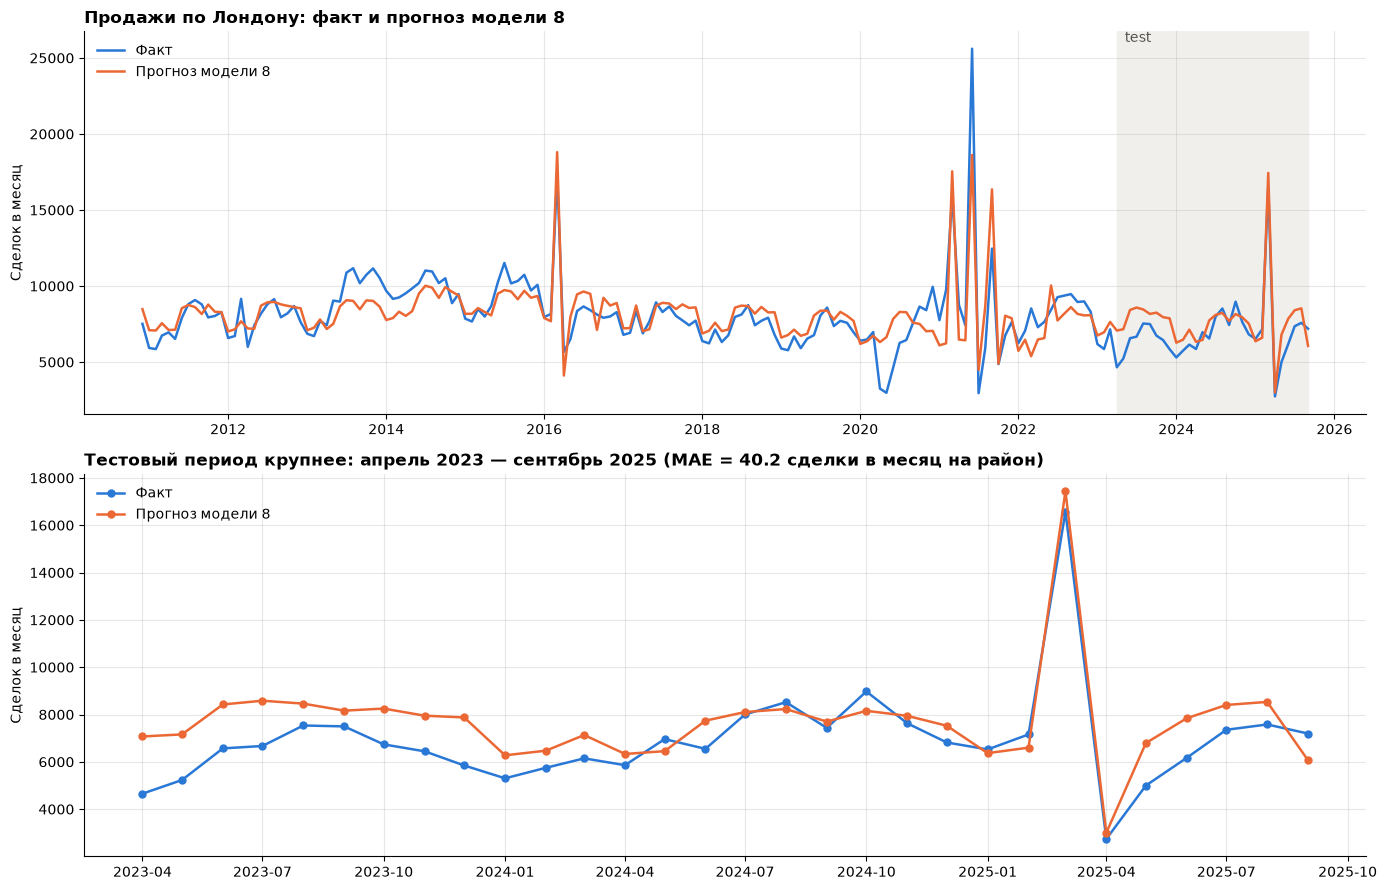

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/Users/user/Downloads/london-property-demand-forecast/.venv/lib/python3.14/site-packages/zmq/eventloop/zmqstream.py", line 585, in _log_error
    f.result()
    ~~~~~~~~^^
  File "/Users/user/Downloads/london-property-demand-forecast/.venv/lib/python3.14/site-packages/ipykernel/kernelbase.py", line 372, in dispatch_control
    await self.process_control(msg)
  File "/Users/user/Downloads/london-property-demand-forecast/.venv/lib/python3.14/site-packages/ipykernel/kernelbase.py", line 378, in process_control
    idents, msg = self.session.feed_identities(msg, copy=False)
                  ~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/Users/user/Downloads/london-property-demand-forecast/.venv/lib/python3.14/site-packages/jupyter_client/session.py", line 998, in feed_identities
    raise ValueError(msg)
ValueError: DELIM not in msg_list
ERROR:tornado.general:Uncaught exceptio

In [285]:
# Прогноз модели 8 по всем месяцам (первые 6 месяцев без лага пропускаем)
d = df.dropna(subset=lag6_cols)
plot_df = d[["month", "sales_count"]].copy()
plot_df["pred"] = model_v8.predict(d[features_v8])

# Суммируем прогноз и факт по всем районам Лондона
monthly = plot_df.groupby("month")[["sales_count", "pred"]].sum()
test_monthly = monthly[monthly.index >= cutoff_v5]
mae_v8 = mean_absolute_error(y_test_v8, model_v8.predict(X_test_v8))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9))

# Вся история: серая зона — тест
ax1.axvspan(cutoff_v5, monthly.index.max(), color="#f0efec", zorder=0)
ax1.plot(monthly.index, monthly["sales_count"], color="#2a78d6", linewidth=1.8, label="Факт")
ax1.plot(monthly.index, monthly["pred"], color="#eb6834", linewidth=1.8, label="Прогноз модели 8")
ax1.text(cutoff_v5, ax1.get_ylim()[1], "  test", va="top", color="#52514e")
ax1.set_title("Продажи по Лондону: факт и прогноз модели 8", loc="left", fontweight="bold")

# Тестовый период крупнее
ax2.plot(test_monthly.index, test_monthly["sales_count"], color="#2a78d6", linewidth=1.8,
         marker="o", markersize=5, label="Факт")
ax2.plot(test_monthly.index, test_monthly["pred"], color="#eb6834", linewidth=1.8,
         marker="o", markersize=5, label="Прогноз модели 8")
ax2.set_title(
    f"Тестовый период крупнее: апрель 2023 — сентябрь 2025 (MAE = {mae_v8:.1f} сделки в месяц на район)",
    loc="left", fontweight="bold",
)

for ax in (ax1, ax2):
    ax.set_ylabel("Сделок в месяц")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.show()